# Visualização de Dados com Python — versão Polars
UNICEUB - AULA 14

Neste notebook vamos trabalhar com o dataset **supermercado_abc_100k_variado.csv** para praticar:

- leitura de dados com **Polars**
- exploração inicial
- criação de indicadores simples
- visualização com Matplotlib e Seaborn

O objetivo é entender como os gráficos ajudam na análise exploratória de dados (EDA).

> **Diferença para a aula original:** em vez de Pandas, usamos Polars para ler e transformar os dados. Polars não tem `.plot()` embutido, então os gráficos são feitos com Matplotlib/Seaborn a partir dos resultados do Polars.

In [1]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

print("Polars:", pl.__version__)

Polars: 1.35.2


## 1. Leitura do arquivo

No Colab, execute a célula abaixo e selecione o arquivo `supermercado_abc_100k_variado.csv` do seu computador.
(Se preferir, monte o Google Drive e ajuste o caminho.)

In [2]:
import os

arquivo = "supermercado_abc_100k_variado.csv"

# No Colab: abre o seletor de arquivo caso o CSV ainda não esteja na sessão
if not os.path.exists(arquivo):
    from google.colab import files
    files.upload()

df = pl.read_csv(arquivo)

print("Dataset carregado com sucesso!")
print(df.head())

Dataset carregado com sucesso!
shape: (5, 23)
┌────────────┬────────────┬───────────┬───────────┬───┬───────────┬─────────┬──────────┬───────────┐
│ id_item    ┆ id_venda   ┆ data_hora ┆ filial_id ┆ … ┆ custo_tot ┆ imposto ┆ comissao ┆ forma_pag │
│ ---        ┆ ---        ┆ ---       ┆ ---       ┆   ┆ al        ┆ ---     ┆ ---      ┆ amento    │
│ str        ┆ str        ┆ str       ┆ str       ┆   ┆ ---       ┆ f64     ┆ f64      ┆ ---       │
│            ┆            ┆           ┆           ┆   ┆ f64       ┆         ┆          ┆ str       │
╞════════════╪════════════╪═══════════╪═══════════╪═══╪═══════════╪═════════╪══════════╪═══════════╡
│ ITEM000001 ┆ VENDA01579 ┆ 2025-05-0 ┆ F04       ┆ … ┆ 13.88     ┆ 1.56    ┆ 0.19     ┆ Cartão    │
│            ┆ 6          ┆ 4         ┆           ┆   ┆           ┆         ┆          ┆ Crédito   │
│            ┆            ┆ 07:05:38  ┆           ┆   ┆           ┆         ┆          ┆           │
│ ITEM000002 ┆ VENDA00086 ┆ 2025-12-0 ┆ F05  

## 2. Conhecendo a estrutura dos dados

Antes de criar gráficos, precisamos entender como os dados estão organizados.

In [3]:
print("Quantidade de linhas e colunas:")
print(df.shape)

print("\nNomes das colunas:")
print(df.columns)

print("\nInformações gerais (nome -> tipo):")
print(df.schema)

print("\nValores nulos por coluna:")
print(df.null_count())

Quantidade de linhas e colunas:
(100000, 23)

Nomes das colunas:
['id_item', 'id_venda', 'data_hora', 'filial_id', 'filial', 'cidade', 'estado', 'caixa', 'operador_caixa', 'id_cliente', 'segmento_cliente', 'produto', 'categoria', 'subcategoria', 'marca', 'quantidade', 'preco_unitario', 'desconto_valor', 'valor_liquido', 'custo_total', 'imposto', 'comissao', 'forma_pagamento']

Informações gerais (nome -> tipo):
Schema({'id_item': String, 'id_venda': String, 'data_hora': String, 'filial_id': String, 'filial': String, 'cidade': String, 'estado': String, 'caixa': String, 'operador_caixa': String, 'id_cliente': String, 'segmento_cliente': String, 'produto': String, 'categoria': String, 'subcategoria': String, 'marca': String, 'quantidade': Int64, 'preco_unitario': Float64, 'desconto_valor': Float64, 'valor_liquido': Float64, 'custo_total': Float64, 'imposto': Float64, 'comissao': Float64, 'forma_pagamento': String})

Valores nulos por coluna:
shape: (1, 23)
┌─────────┬──────────┬──────────

## 3. Ajustando tipos de dados

Vamos converter a coluna de data e garantir que as colunas numéricas sejam `Float64`, para que cálculos e gráficos funcionem corretamente.
Em Polars usamos `with_columns` + expressões (`pl.col`). Com `strict=False`, valores inválidos viram `null` (equivale ao `errors="coerce"` do Pandas).

In [4]:
colunas_numericas = [
    "quantidade",
    "preco_unitario",
    "desconto_valor",
    "valor_liquido",
    "custo_total",
    "imposto",
    "comissao",
]

df = df.with_columns(
    pl.col("data_hora").str.to_datetime("%Y-%m-%d %H:%M:%S", strict=False),
    pl.col(colunas_numericas).cast(pl.Float64, strict=False),
)

print(df.schema)

Schema({'id_item': String, 'id_venda': String, 'data_hora': Datetime(time_unit='us', time_zone=None), 'filial_id': String, 'filial': String, 'cidade': String, 'estado': String, 'caixa': String, 'operador_caixa': String, 'id_cliente': String, 'segmento_cliente': String, 'produto': String, 'categoria': String, 'subcategoria': String, 'marca': String, 'quantidade': Float64, 'preco_unitario': Float64, 'desconto_valor': Float64, 'valor_liquido': Float64, 'custo_total': Float64, 'imposto': Float64, 'comissao': Float64, 'forma_pagamento': String})


## 4. Estatísticas básicas

Agora vamos observar algumas estatísticas das colunas numéricas.

In [5]:
print(df.select(colunas_numericas).describe())

shape: (9, 8)
┌────────────┬────────────┬────────────┬───────────┬───────────┬───────────┬───────────┬───────────┐
│ statistic  ┆ quantidade ┆ preco_unit ┆ desconto_ ┆ valor_liq ┆ custo_tot ┆ imposto   ┆ comissao  │
│ ---        ┆ ---        ┆ ario       ┆ valor     ┆ uido      ┆ al        ┆ ---       ┆ ---       │
│ str        ┆ f64        ┆ ---        ┆ ---       ┆ ---       ┆ ---       ┆ f64       ┆ f64       │
│            ┆            ┆ f64        ┆ f64       ┆ f64       ┆ f64       ┆           ┆           │
╞════════════╪════════════╪════════════╪═══════════╪═══════════╪═══════════╪═══════════╪═══════════╡
│ count      ┆ 100000.0   ┆ 100000.0   ┆ 100000.0  ┆ 100000.0  ┆ 100000.0  ┆ 100000.0  ┆ 100000.0  │
│ null_count ┆ 0.0        ┆ 0.0        ┆ 0.0       ┆ 0.0       ┆ 0.0       ┆ 0.0       ┆ 0.0       │
│ mean       ┆ 2.38128    ┆ 20.446681  ┆ 2.135694  ┆ 46.806803 ┆ 34.311705 ┆ 4.0976457 ┆ 0.5509309 │
│ std        ┆ 1.900742   ┆ 29.530654  ┆ 7.422767  ┆ 95.871403 ┆ 69.918798 ┆ 

## 5. Gráfico 1 – Vendas por categoria

Vamos somar o valor líquido por categoria e criar um gráfico de barras.

In [6]:
vendas_categoria = (
    df.group_by("categoria")
      .agg(pl.col("valor_liquido").sum())
      .sort("categoria")
)

print(vendas_categoria)

shape: (5, 2)
┌─────────────┬───────────────┐
│ categoria   ┆ valor_liquido │
│ ---         ┆ ---           │
│ str         ┆ f64           │
╞═════════════╪═══════════════╡
│ Alimentos   ┆ 1.5936e6      │
│ Bebidas     ┆ 329969.57     │
│ Eletronicos ┆ 2.0692e6      │
│ Higiene     ┆ 338324.19     │
│ Limpeza     ┆ 349586.89     │
└─────────────┴───────────────┘


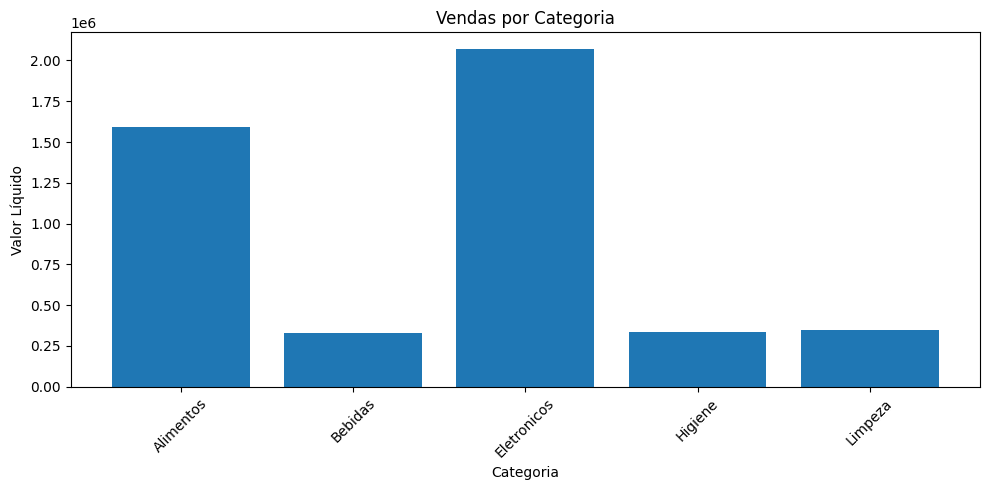

In [7]:
plt.figure(figsize=(10, 5))
plt.bar(vendas_categoria["categoria"], vendas_categoria["valor_liquido"])

plt.title("Vendas por Categoria")
plt.xlabel("Categoria")
plt.ylabel("Valor Líquido")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Gráfico 2 – Vendas por forma de pagamento

Agora vamos comparar as formas de pagamento.

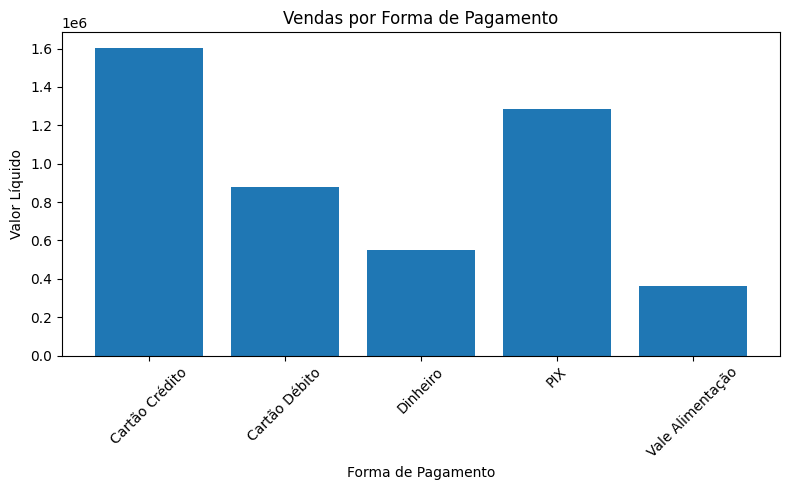

In [8]:
vendas_pagamento = (
    df.group_by("forma_pagamento")
      .agg(pl.col("valor_liquido").sum())
      .sort("forma_pagamento")
)

plt.figure(figsize=(8, 5))
plt.bar(vendas_pagamento["forma_pagamento"], vendas_pagamento["valor_liquido"])

plt.title("Vendas por Forma de Pagamento")
plt.xlabel("Forma de Pagamento")
plt.ylabel("Valor Líquido")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Gráfico 3 – Histograma com Seaborn

O histograma mostra a distribuição dos valores da coluna `valor_liquido`.
Passamos a coluna do Polars convertida para NumPy (`.to_numpy()`) para o Seaborn.

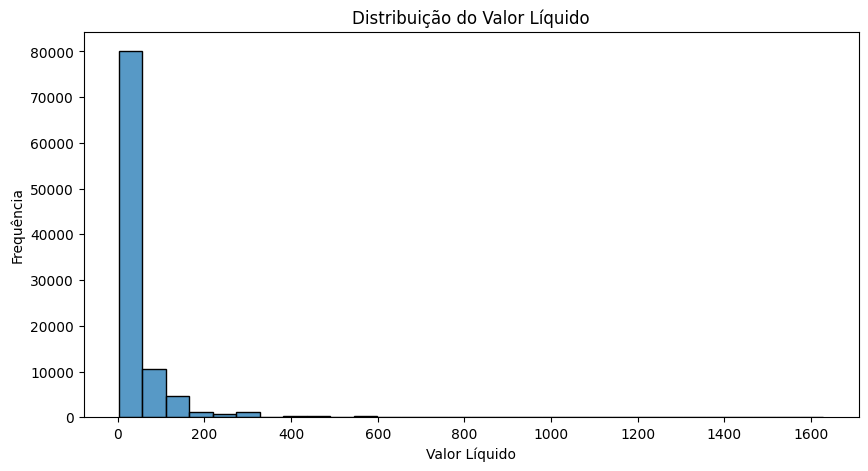

In [9]:
plt.figure(figsize=(10, 5))
sns.histplot(df["valor_liquido"].to_numpy(), bins=30)

plt.title("Distribuição do Valor Líquido")
plt.xlabel("Valor Líquido")
plt.ylabel("Frequência")
plt.show()

## 8. Gráfico 4 – Boxplot

O boxplot ajuda a visualizar dispersão e possíveis valores extremos.

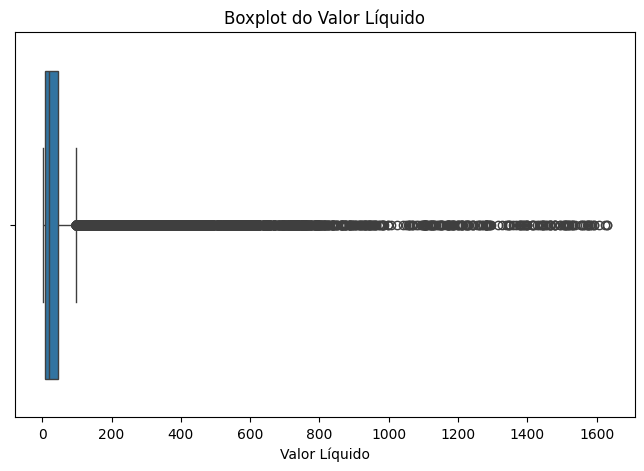

In [10]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["valor_liquido"].to_numpy())

plt.title("Boxplot do Valor Líquido")
plt.xlabel("Valor Líquido")
plt.show()

## 9. Criando coluna de data

Vamos extrair apenas a data para analisar vendas ao longo do tempo.

In [11]:
df = df.with_columns(pl.col("data_hora").dt.date().alias("data"))

print(df.select("data_hora", "data").head())

shape: (5, 2)
┌─────────────────────┬────────────┐
│ data_hora           ┆ data       │
│ ---                 ┆ ---        │
│ datetime[μs]        ┆ date       │
╞═════════════════════╪════════════╡
│ 2025-05-04 07:05:38 ┆ 2025-05-04 │
│ 2025-12-06 04:43:50 ┆ 2025-12-06 │
│ 2025-08-13 06:24:59 ┆ 2025-08-13 │
│ 2025-04-20 09:02:14 ┆ 2025-04-20 │
│ 2026-07-24 09:20:03 ┆ 2026-07-24 │
└─────────────────────┴────────────┘


## 10. Gráfico 5 – Vendas por data

Agora vamos analisar a evolução do valor vendido por dia.
No Polars, `group_by` não garante ordem, então usamos `.sort("data")` para a linha do tempo ficar correta.

In [12]:
vendas_data = (
    df.group_by("data")
      .agg(pl.col("valor_liquido").sum())
      .sort("data")
)

print(vendas_data.head())

shape: (5, 2)
┌────────────┬───────────────┐
│ data       ┆ valor_liquido │
│ ---        ┆ ---           │
│ date       ┆ f64           │
╞════════════╪═══════════════╡
│ 2025-01-01 ┆ 4271.6        │
│ 2025-01-02 ┆ 6753.29       │
│ 2025-01-03 ┆ 6720.9        │
│ 2025-01-04 ┆ 8630.82       │
│ 2025-01-05 ┆ 6245.31       │
└────────────┴───────────────┘


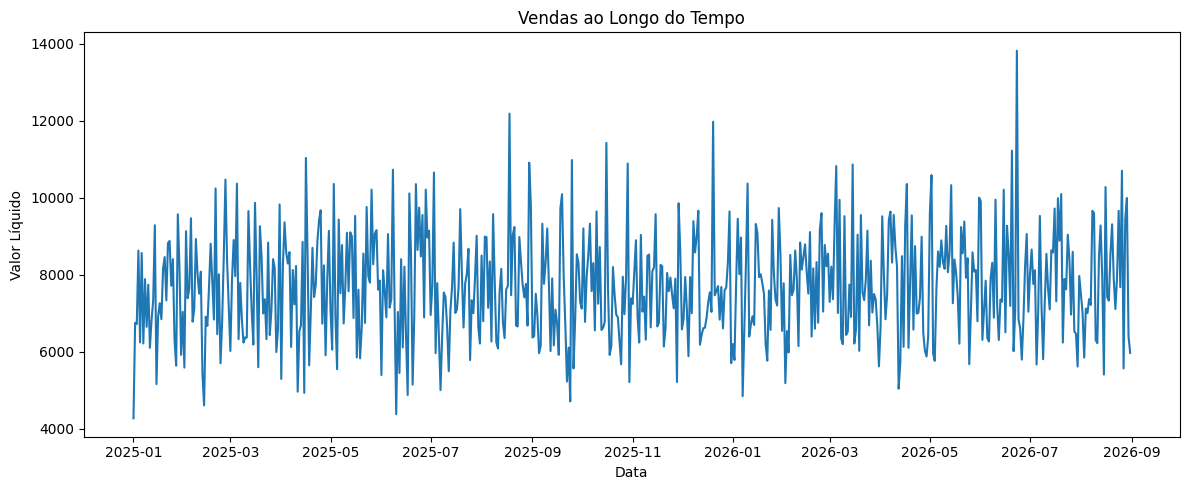

In [13]:
plt.figure(figsize=(12, 5))
plt.plot(vendas_data["data"], vendas_data["valor_liquido"])

plt.title("Vendas ao Longo do Tempo")
plt.xlabel("Data")
plt.ylabel("Valor Líquido")
plt.tight_layout()
plt.show()

## 11. Gráfico 6 – Top 10 produtos mais vendidos

Vamos descobrir quais produtos mais apareceram nas vendas.

In [14]:
top_produtos = df["produto"].value_counts(sort=True).head(10)

print(top_produtos)

shape: (10, 2)
┌──────────────────────┬───────┐
│ produto              ┆ count │
│ ---                  ┆ ---   │
│ str                  ┆ u32   │
╞══════════════════════╪═══════╡
│ Arroz 5kg            ┆ 11512 │
│ Feijão 1kg           ┆ 9021  │
│ Refrigerante 2L      ┆ 8056  │
│ Café 500g            ┆ 7552  │
│ Macarrão 500g        ┆ 7462  │
│ Leite 1L             ┆ 6475  │
│ Açúcar 1kg           ┆ 6193  │
│ Detergente 500ml     ┆ 5442  │
│ Papel Higiênico 12un ┆ 4981  │
│ Suco 1L              ┆ 4480  │
└──────────────────────┴───────┘


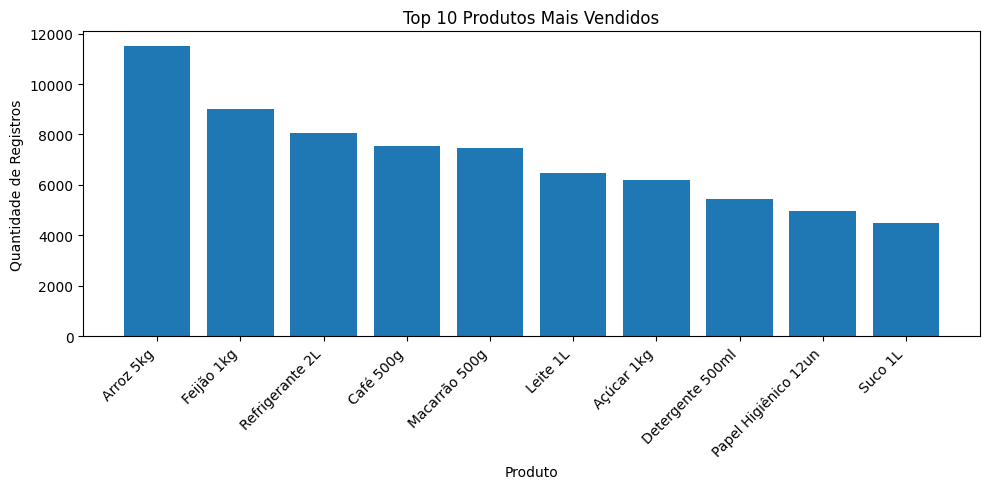

In [15]:
plt.figure(figsize=(10, 5))
plt.bar(top_produtos["produto"], top_produtos["count"])

plt.title("Top 10 Produtos Mais Vendidos")
plt.xlabel("Produto")
plt.ylabel("Quantidade de Registros")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 12. Gráfico 7 – Valor líquido médio por categoria com Seaborn

Agora vamos analisar a média de valor por categoria.

In [16]:
media_categoria = (
    df.group_by("categoria")
      .agg(pl.col("valor_liquido").mean())
      .sort("categoria")
)

print(media_categoria)

shape: (5, 2)
┌─────────────┬───────────────┐
│ categoria   ┆ valor_liquido │
│ ---         ┆ ---           │
│ str         ┆ f64           │
╞═════════════╪═══════════════╡
│ Alimentos   ┆ 33.051954     │
│ Bebidas     ┆ 19.395143     │
│ Eletronicos ┆ 206.465743    │
│ Higiene     ┆ 31.202083     │
│ Limpeza     ┆ 25.137477     │
└─────────────┴───────────────┘


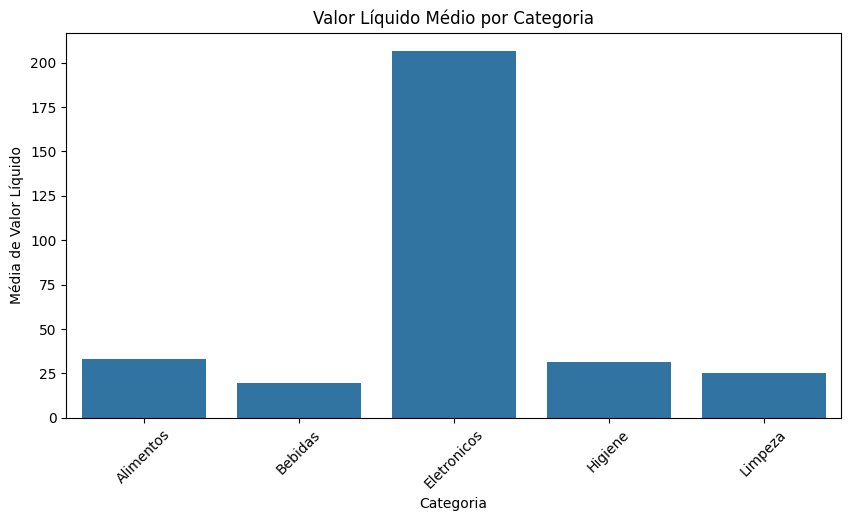

In [17]:
plt.figure(figsize=(10, 5))
sns.barplot(
    x=media_categoria["categoria"].to_list(),
    y=media_categoria["valor_liquido"].to_list(),
)

plt.title("Valor Líquido Médio por Categoria")
plt.xlabel("Categoria")
plt.ylabel("Média de Valor Líquido")
plt.xticks(rotation=45)
plt.show()

## 13. Gráfico 8 – Relação entre preço unitário e valor líquido

Esse gráfico ajuda a observar como duas variáveis numéricas se comportam.
`df.sample(1000, seed=42)` é o equivalente Polars de `random_state=42`.

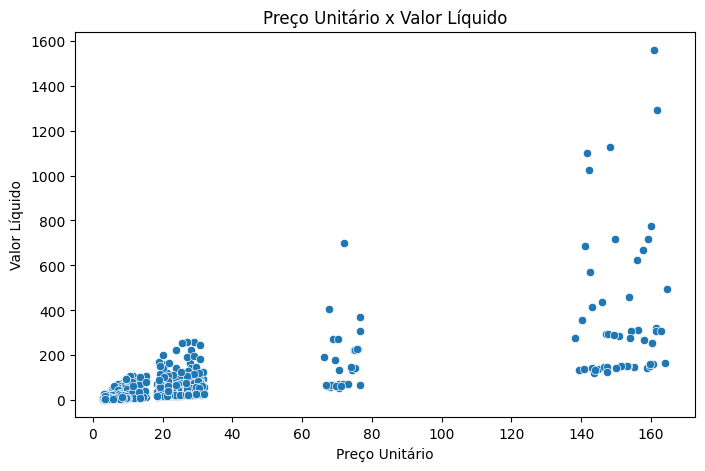

In [18]:
amostra = df.sample(1000, seed=42)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=amostra["preco_unitario"].to_numpy(),
    y=amostra["valor_liquido"].to_numpy(),
)

plt.title("Preço Unitário x Valor Líquido")
plt.xlabel("Preço Unitário")
plt.ylabel("Valor Líquido")
plt.show()

## 14. Resumo final

Com esse notebook foi possível:

- carregar um dataset real com Polars
- explorar a estrutura dos dados
- converter tipos com expressões (`with_columns`, `pl.col`)
- gerar estatísticas básicas
- agregar dados com `group_by().agg()`
- criar diferentes tipos de gráficos com Matplotlib e Seaborn

### Tabela de equivalência Pandas → Polars

| Pandas | Polars |
|---|---|
| `pd.read_csv` | `pl.read_csv` |
| `df.info()` | `df.schema` / `df.null_count()` |
| `pd.to_datetime(col)` | `pl.col(c).str.to_datetime()` |
| `df[c] = ...` | `df.with_columns(...)` |
| `df.groupby(c)[v].sum()` | `df.group_by(c).agg(pl.col(v).sum())` |
| `s.value_counts()` | `s.value_counts(sort=True)` |
| `df.sample(n, random_state=42)` | `df.sample(n, seed=42)` |
| `df.plot(...)` | não existe → Matplotlib/Seaborn |

---
# Parte 2 — Interpretação de Modelos KNN na Prática
UNICEUB - AULA 15

Agora vamos usar o **K-Nearest Neighbors (KNN)** para **prever a categoria do produto** (`categoria`) a partir das demais variáveis, e principalmente **interpretar** o resultado:

1. Avaliar o modelo (acurácia)
2. Entender as métricas (precision, recall, F1)
3. Localizar os erros (matriz de confusão)
4. Identificar melhorias

O Polars cuida da preparação dos dados; o scikit-learn recebe os arrays NumPy (`.to_numpy()`).

In [19]:
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## 15. Preparando os dados para o modelo

O KNN trabalha com distância, então precisa de entradas **numéricas**. Três colunas da lista da aula (`filial_id`, `caixa`, `id_cliente`) vêm como **texto com código** (`F04`, `CX02`, `CLI016985`).
Vamos extrair a parte numérica de cada uma com uma expressão regular do Polars (`str.extract`).

In [20]:
colunas_codigo = ["filial_id", "caixa", "id_cliente"]

df_ml = df.with_columns(
    pl.col(colunas_codigo).str.extract(r"(\d+)").cast(pl.Int64)
)

print(df_ml.select(colunas_codigo).head())

shape: (5, 3)
┌───────────┬───────┬────────────┐
│ filial_id ┆ caixa ┆ id_cliente │
│ ---       ┆ ---   ┆ ---        │
│ i64       ┆ i64   ┆ i64        │
╞═══════════╪═══════╪════════════╡
│ 4         ┆ 2     ┆ 16985      │
│ 5         ┆ 5     ┆ 4868       │
│ 2         ┆ 2     ┆ 10847      │
│ 1         ┆ 5     ┆ 12118      │
│ 4         ┆ 8     ┆ 7610       │
└───────────┴───────┴────────────┘


## 16. Aplicando o KNN para prever a categoria do produto (Célula 34)

- **Alvo:** `categoria`
- **Divisão:** 75% treino / 25% teste, com `stratify` para manter a proporção das classes
- **Padronização:** `StandardScaler` (KNN é sensível à escala) — ajustado **só no treino**
- **Modelo:** `KNeighborsClassifier(n_neighbors=5)`

In [21]:
# Vamos prever a categoria do produto
coluna_alvo = "categoria"

# Variáveis numéricas usadas pelo modelo
colunas_modelo = [
    "filial_id",
    "caixa",
    "id_cliente",
    "quantidade",
    "preco_unitario",
    "desconto_valor",
    "valor_liquido",
    "custo_total",
    "imposto",
    "comissao",
]

# Separando variáveis explicativas e variável alvo (Polars -> NumPy)
X = df_ml.select(colunas_modelo).to_numpy()
y = df_ml[coluna_alvo].to_numpy()

# Divisão entre treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y,
)

# Padronização dos dados
scaler = StandardScaler()
X_treino_padronizado = scaler.fit_transform(X_treino)
X_teste_padronizado = scaler.transform(X_teste)

# Criação e treinamento do modelo KNN
modelo_knn = KNeighborsClassifier(n_neighbors=5)
modelo_knn.fit(X_treino_padronizado, y_treino)

# Previsões
y_pred = modelo_knn.predict(X_teste_padronizado)

# Avaliação do modelo
acuracia = accuracy_score(y_teste, y_pred)

print("Resultado do Modelo KNN")
print("-" * 40)
print(f"Acurácia: {acuracia:.2%}")

print("\nRelatório de Classificação:")
print(classification_report(y_teste, y_pred))

print("\nMatriz de Confusão:")
print(confusion_matrix(y_teste, y_pred))

Resultado do Modelo KNN
----------------------------------------
Acurácia: 59.61%

Relatório de Classificação:
              precision    recall  f1-score   support

   Alimentos       0.62      0.87      0.72     12054
     Bebidas       0.48      0.35      0.40      4253
 Eletronicos       0.92      0.76      0.83      2505
     Higiene       0.35      0.19      0.24      2711
     Limpeza       0.36      0.14      0.20      3477

    accuracy                           0.60     25000
   macro avg       0.55      0.46      0.48     25000
weighted avg       0.56      0.60      0.56     25000


Matriz de Confusão:
[[10529   603    85   525   312]
 [ 2354  1470     0   103   326]
 [  484     0  1898    44    79]
 [ 1491   524    19   509   168]
 [ 2175   469    64   272   497]]


## 17. Acurácia: o que 59,6% quer dizer?

**Acurácia = total de acertos ÷ total de previsões.** É intuitiva, mas não diz *onde* o modelo erra.

Um número isolado não significa nada: precisamos de um **ponto de comparação**. Em um problema de 5 classes **balanceadas**, chutar aleatoriamente acertaria ~20%. Só que **este dataset não é balanceado**. Veja abaixo a distribuição das classes e o que um "modelo bobo" que só responde a classe mais comum conseguiria.

In [22]:
distribuicao = (
    df_ml["categoria"]
    .value_counts(sort=True)
    .with_columns((pl.col("count") / pl.col("count").sum()).alias("proporcao"))
)
print(distribuicao)

classe_majoritaria = distribuicao["categoria"][0]
baseline = (y_teste == classe_majoritaria).mean()
print(f"\nBaseline (sempre prever '{classe_majoritaria}'): {baseline:.2%}")
print(f"Acurácia do KNN: {acuracia:.2%}")

shape: (5, 3)
┌─────────────┬───────┬───────────┐
│ categoria   ┆ count ┆ proporcao │
│ ---         ┆ ---   ┆ ---       │
│ str         ┆ u32   ┆ f64       │
╞═════════════╪═══════╪═══════════╡
│ Alimentos   ┆ 48215 ┆ 0.48215   │
│ Bebidas     ┆ 17013 ┆ 0.17013   │
│ Limpeza     ┆ 13907 ┆ 0.13907   │
│ Higiene     ┆ 10843 ┆ 0.10843   │
│ Eletronicos ┆ 10022 ┆ 0.10022   │
└─────────────┴───────┴───────────┘

Baseline (sempre prever 'Alimentos'): 48.22%
Acurácia do KNN: 59.61%


**Leitura:** o KNN (≈ 59,6%) supera o baseline (≈ 48,2%), então aprendeu *alguma* coisa — mas pouco. A armadilha da acurácia aparece aqui: como "Alimentos" é quase metade dos dados, parte desse resultado vem só de acertar a classe dominante. Precisamos olhar **por classe**.

## 18. Precision, Recall e F1-Score por categoria

- **Precision:** das vezes que o modelo disse "classe X", quantas estavam certas? (confiabilidade; baixa = muitos falsos positivos)
- **Recall:** dos itens que realmente são "classe X", quantos o modelo achou? (cobertura; baixo = muitos falsos negativos)
- **F1-Score:** média harmônica entre os dois (penaliza quando um deles é muito baixo)

In [23]:
relatorio = classification_report(y_teste, y_pred, output_dict=True)

classes = list(modelo_knn.classes_)
metricas = pl.DataFrame({
    "categoria": classes,
    "precision": [relatorio[c]["precision"] for c in classes],
    "recall":    [relatorio[c]["recall"] for c in classes],
    "f1_score":  [relatorio[c]["f1-score"] for c in classes],
    "suporte":   [int(relatorio[c]["support"]) for c in classes],
}).with_columns(pl.col(["precision", "recall", "f1_score"]).round(3))

print(metricas)

shape: (5, 5)
┌─────────────┬───────────┬────────┬──────────┬─────────┐
│ categoria   ┆ precision ┆ recall ┆ f1_score ┆ suporte │
│ ---         ┆ ---       ┆ ---    ┆ ---      ┆ ---     │
│ str         ┆ f64       ┆ f64    ┆ f64      ┆ i64     │
╞═════════════╪═══════════╪════════╪══════════╪═════════╡
│ Alimentos   ┆ 0.618     ┆ 0.873  ┆ 0.724    ┆ 12054   │
│ Bebidas     ┆ 0.479     ┆ 0.346  ┆ 0.402    ┆ 4253    │
│ Eletronicos ┆ 0.919     ┆ 0.758  ┆ 0.83     ┆ 2505    │
│ Higiene     ┆ 0.35      ┆ 0.188  ┆ 0.244    ┆ 2711    │
│ Limpeza     ┆ 0.36      ┆ 0.143  ┆ 0.205    ┆ 3477    │
└─────────────┴───────────┴────────┴──────────┴─────────┘


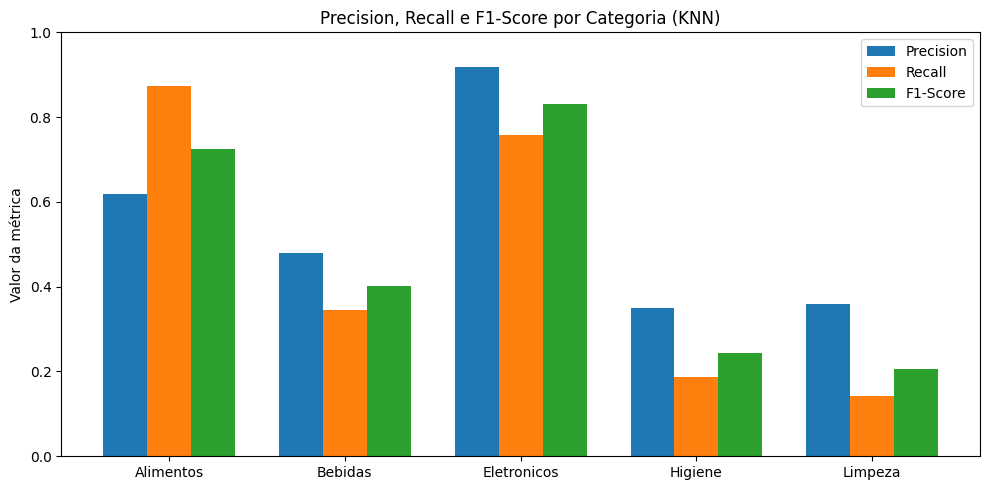

In [24]:
x = np.arange(len(classes))
largura = 0.25

plt.figure(figsize=(10, 5))
plt.bar(x - largura, metricas["precision"], largura, label="Precision")
plt.bar(x,           metricas["recall"],    largura, label="Recall")
plt.bar(x + largura, metricas["f1_score"],  largura, label="F1-Score")

plt.xticks(x, classes)
plt.ylim(0, 1)
plt.title("Precision, Recall e F1-Score por Categoria (KNN)")
plt.ylabel("Valor da métrica")
plt.legend()
plt.tight_layout()
plt.show()

**Como ler esse gráfico (valores do relatório acima):**

- **Eletrônicos** vai bem (precision ≈ 0,92 | recall ≈ 0,76): o preço alto ajuda o KNN a separar essa classe.
- **Alimentos** tem recall alto (≈ 0,87) mas precision mediana (≈ 0,62): o modelo "acusa" Alimentos com muita facilidade, ou seja, **muitos falsos positivos**.
- **Higiene e Limpeza** vão mal (recall ≈ 0,19 e ≈ 0,14): o modelo **perde mais de 80% dos itens reais** dessas classes.

Ou seja, a acurácia geral escondia um desempenho muito desigual entre as categorias.

## 19. Matriz de Confusão: onde o modelo erra?

- **Linhas:** classe real
- **Colunas:** classe prevista
- **Diagonal principal:** acertos

À direita, a mesma matriz **normalizada por linha** (cada linha soma 100%): a diagonal passa a ser o **recall** de cada classe.

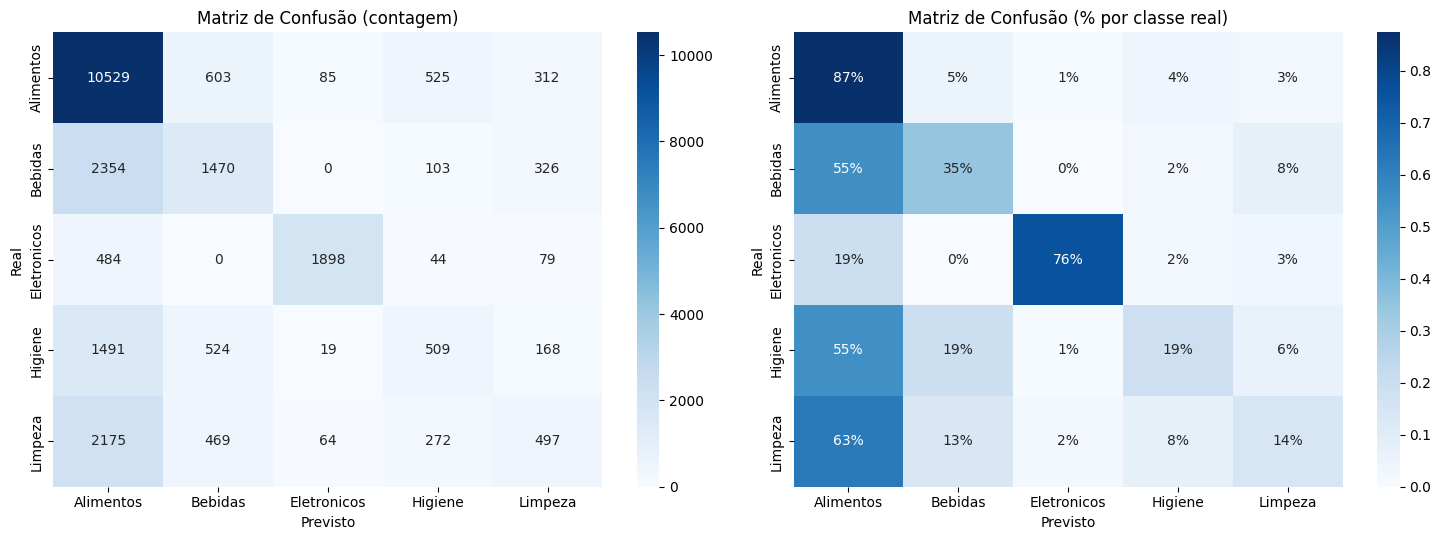

In [25]:
cm = confusion_matrix(y_teste, y_pred, labels=classes)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, eixos = plt.subplots(1, 2, figsize=(15, 5.5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes, ax=eixos[0])
eixos[0].set_title("Matriz de Confusão (contagem)")
eixos[0].set_xlabel("Previsto")
eixos[0].set_ylabel("Real")

sns.heatmap(cm_norm, annot=True, fmt=".0%", cmap="Blues",
            xticklabels=classes, yticklabels=classes, ax=eixos[1])
eixos[1].set_title("Matriz de Confusão (% por classe real)")
eixos[1].set_xlabel("Previsto")
eixos[1].set_ylabel("Real")

plt.tight_layout()
plt.show()

**O que a matriz mostra:** a coluna **Alimentos** concentra boa parte das previsões. Itens reais de Bebidas, Higiene e Limpeza são, na maioria das vezes, previstos como Alimentos (por exemplo, só ~14% dos itens de Limpeza foram reconhecidos). Já Eletrônicos é bem reconhecido e raramente é confundido com Bebidas, Higiene ou Limpeza (quando erra, erra para Alimentos). Isso indica que, para essas categorias, **as variáveis de entrada não separam bem os grupos**.

## 20. Diagnóstico: por que o modelo foi fraco?

- **Variáveis irrelevantes:** `filial_id`, `caixa` e `id_cliente` são **identificadores**. O número do cliente ou do caixa não diz nada sobre a categoria do produto, mas entram no cálculo de distância como se fossem medidas.
- **KNN depende de distância:** só funciona se itens parecidos estiverem "próximos" no espaço das variáveis. Códigos de ID bagunçam essa proximidade.
- **Classes desbalanceadas:** os vizinhos de qualquer ponto tendem a ser de "Alimentos", simplesmente porque há muito mais deles.

Vamos **testar essas hipóteses** em vez de apenas supô-las.

## 21. Melhorando o modelo

### 21.1 Melhorar os dados: remover os identificadores

Mesmo KNN, mesmo `k=5`, mesma divisão treino/teste. A **única** mudança é tirar `filial_id`, `caixa` e `id_cliente`.

In [26]:
colunas_sem_ids = [c for c in colunas_modelo if c not in colunas_codigo]
print("Variáveis usadas:", colunas_sem_ids)

X2 = df_ml.select(colunas_sem_ids).to_numpy()

X2_treino, X2_teste, y2_treino, y2_teste = train_test_split(
    X2, y,
    test_size=0.25,
    random_state=42,
    stratify=y,
)

scaler2 = StandardScaler()
X2_treino_p = scaler2.fit_transform(X2_treino)
X2_teste_p = scaler2.transform(X2_teste)

knn_sem_ids = KNeighborsClassifier(n_neighbors=5).fit(X2_treino_p, y2_treino)
y_pred2 = knn_sem_ids.predict(X2_teste_p)

print(f"\nAcurácia KNN com IDs : {acuracia:.2%}")
print(f"Acurácia KNN sem IDs : {accuracy_score(y2_teste, y_pred2):.2%}")

print("\nRelatório de Classificação (KNN sem IDs):")
print(classification_report(y2_teste, y_pred2))

Variáveis usadas: ['quantidade', 'preco_unitario', 'desconto_valor', 'valor_liquido', 'custo_total', 'imposto', 'comissao']

Acurácia KNN com IDs : 59.61%
Acurácia KNN sem IDs : 83.21%

Relatório de Classificação (KNN sem IDs):
              precision    recall  f1-score   support

   Alimentos       0.85      0.94      0.89     12054
     Bebidas       0.79      0.71      0.75      4253
 Eletronicos       0.94      0.88      0.91      2505
     Higiene       0.85      0.79      0.82      2711
     Limpeza       0.71      0.62      0.66      3477

    accuracy                           0.83     25000
   macro avg       0.83      0.79      0.81     25000
weighted avg       0.83      0.83      0.83     25000



### 21.2 Testar outros algoritmos

Agora, com as variáveis já limpas, comparamos o KNN com os algoritmos sugeridos na aula:

- **Regressão Logística:** modelo linear
- **Árvore de Decisão:** regras interpretáveis
- **Random Forest:** conjunto de árvores, mais robusto

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

modelos = {
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Regressão Logística": LogisticRegression(max_iter=1000),
    "Árvore de Decisão": DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
}

resultados = [("KNN com IDs (modelo da aula)", acuracia)]

for nome, modelo in modelos.items():
    modelo.fit(X2_treino_p, y2_treino)
    resultados.append((nome + " — sem IDs", accuracy_score(y2_teste, modelo.predict(X2_teste_p))))

resultados.append((f"Baseline (sempre '{classe_majoritaria}')", baseline))

tabela = (
    pl.DataFrame(resultados, schema=["modelo", "acuracia"], orient="row")
    .sort("acuracia", descending=True)
    .with_columns(pl.col("acuracia").round(4))
)
print(tabela)

shape: (6, 2)
┌───────────────────────────────┬──────────┐
│ modelo                        ┆ acuracia │
│ ---                           ┆ ---      │
│ str                           ┆ f64      │
╞═══════════════════════════════╪══════════╡
│ Random Forest — sem IDs       ┆ 0.8805   │
│ Árvore de Decisão — sem IDs   ┆ 0.8352   │
│ KNN (k=5) — sem IDs           ┆ 0.8321   │
│ KNN com IDs (modelo da aula)  ┆ 0.5961   │
│ Regressão Logística — sem IDs ┆ 0.5805   │
│ Baseline (sempre 'Alimentos') ┆ 0.4822   │
└───────────────────────────────┴──────────┘


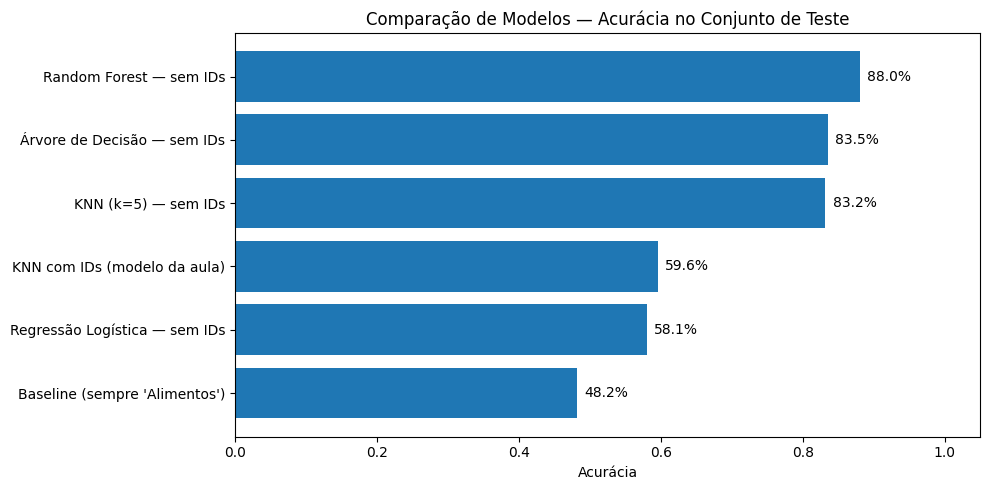

In [28]:
plt.figure(figsize=(10, 5))
ordem = tabela.sort("acuracia")   # barras horizontais: menor embaixo
plt.barh(ordem["modelo"], ordem["acuracia"])

for i, v in enumerate(ordem["acuracia"]):
    plt.text(v + 0.01, i, f"{v:.1%}", va="center")

plt.xlim(0, 1.05)
plt.title("Comparação de Modelos — Acurácia no Conjunto de Teste")
plt.xlabel("Acurácia")
plt.tight_layout()
plt.show()

## 22. A grande questão: o problema é o algoritmo ou os dados?

Com os números na mão:

| Passo | O que mudou | Acurácia |
|---|---|---|
| Baseline | prever sempre "Alimentos" | ≈ 48,2% |
| KNN da aula | 10 variáveis (3 são IDs) | ≈ 59,6% |
| KNN sem IDs | **só os dados** (removeu 3 colunas) | ≈ 83,2% |
| Random Forest sem IDs | **dados + algoritmo** | ≈ 88,1% |

**Conclusão:** a maior parte da melhora (~24 pontos percentuais) veio de **limpar os dados**, sem trocar o algoritmo. Trocar de KNN para Random Forest somou mais uns ~5 pontos. É o *"garbage in, garbage out"*: variáveis sem informação atrapalham até um algoritmo que seria bom.

> Um modelo ruim não é fracasso, é **informação**. Ele nos disse que algo nos dados precisava mudar.

**Ciclo da aula:** Acurácia (visão geral) → Precision & Recall (por classe) → Matriz de Confusão (padrão de erros) → Ação (melhorar dados e algoritmos).

### Próximos passos possíveis
- Testar valores de `k` diferentes no KNN (3, 7, 15...)
- Usar `class_weight="balanced"` ou reamostragem para lidar com o desbalanceamento
- Criar *features* novas (ex.: margem = `valor_liquido - custo_total`, percentual de desconto)
- Olhar a importância das variáveis no Random Forest (`feature_importances_`)